**Install and import libraries**

In [33]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.metrics import recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


**Upload dataset**

In [34]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Saving train.csv to train (1).csv
Dataset uploaded successfully!
Dataset Shape: (298, 8)


,Rear_Main_Camera_MP,Rear_Camera_Count,Front_Camera_MP,Price_Range_INR,RAM_GB,Storage_GB,Battery_mAh,Display_Size_inches
0,50,3,8,"10,000-14,999",16,128,7000,6.4
1,32,2,8,"25,000-39,999",16,256,7000,6.6
2,48,3,8,"10,000-14,999",8,128,5000,6.7
3,48,3,20,"15,000-24,999",16,256,5000,6.6
4,50,4,13,"25,000-39,999",32,64,5000,6.5


**Data preprocessing**

In [35]:
target = "Price_Range_INR"

df.columns = df.columns.str.strip()

# Clean target labels
df[target] = df[target].astype(str).str.strip()
df[target] = df[target].str.replace("₹", "", regex=False)

# Remove missing values
df = df.dropna()

# Separate input and output
X = df.drop(columns=[target])
y = df[target]

print("Input Features:")
print(X.columns.tolist())

print("\nPrice Classes:")
print(y.value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

Input Features:
['Rear_Main_Camera_MP', 'Rear_Camera_Count', 'Front_Camera_MP', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_Size_inches']

Price Classes:
Price_Range_INR
5,000-9,999      75
15,000-24,999    75
25,000-39,999    74
10,000-14,999    74
Name: count, dtype: int64

Missing Values:
Rear_Main_Camera_MP    0
Rear_Camera_Count      0
Front_Camera_MP        0
Price_Range_INR        0
RAM_GB                 0
Storage_GB             0
Battery_mAh            0
Display_Size_inches    0
dtype: int64

Final Dataset Shape: (298, 8)


**Price range distribution**

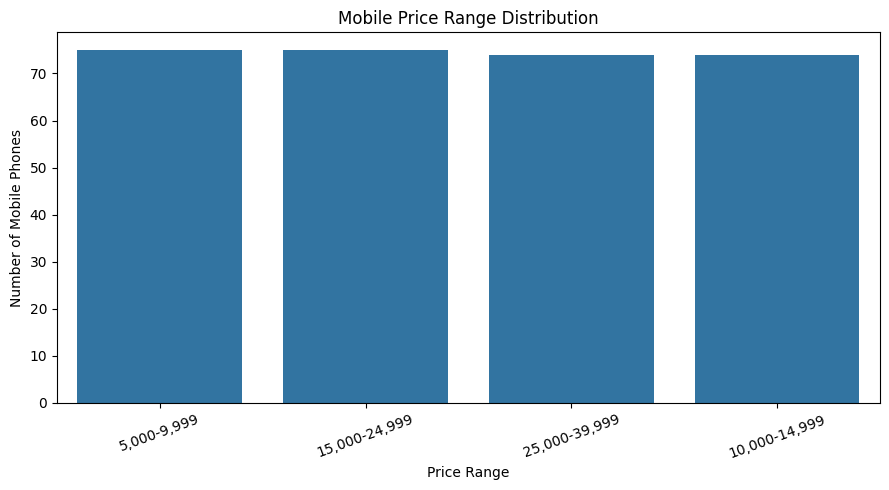

In [36]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x=target,
    order=df[target].value_counts().index
)

plt.title("Mobile Price Range Distribution")
plt.xlabel("Price Range")
plt.ylabel("Number of Mobile Phones")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Correlation heatmap**

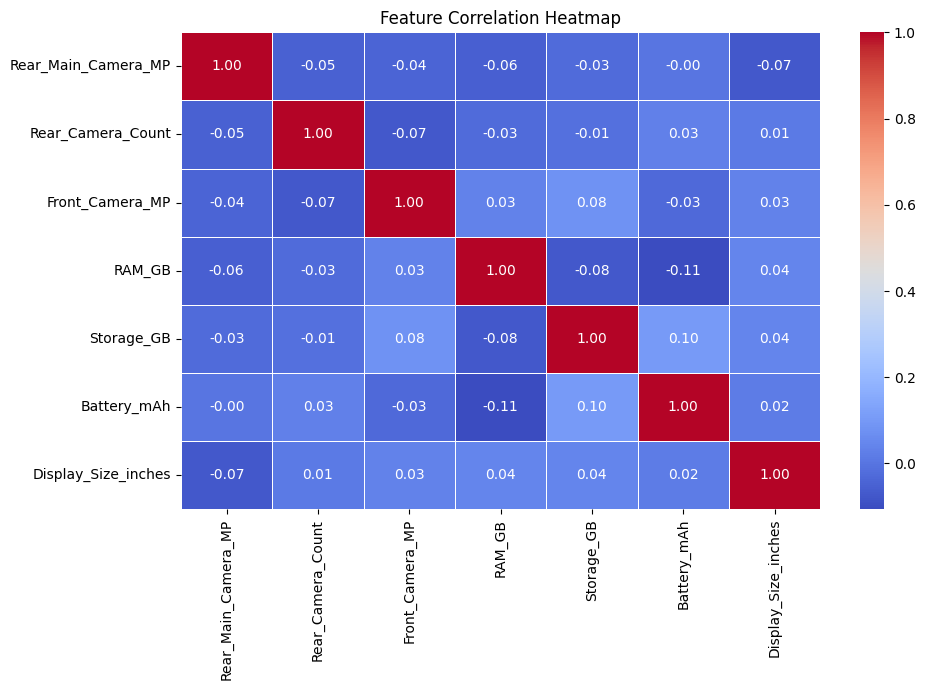

In [37]:
plt.figure(figsize=(10, 7))

correlation = X.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

**Define machine learning models**

In [40]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Main SVM Model
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

# Other models for accuracy comparison
models = {
    "SVM": svm_model,

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("SVM is the main model!")

SVM is the main model!


**Compare model accuracy**

In [41]:
results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Accuracy (%)": round(scores.mean() * 100, 2),
        "Standard Deviation (%)": round(scores.std() * 100, 2)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
)

display(results_df)

print("Main Model: SVM")

,Model,Accuracy (%),Standard Deviation (%)
0,SVM,52.38,5.87
2,Extra Trees,50.36,6.13
4,Logistic Regression,48.33,6.60
1,Random Forest,48.01,4.44
5,Gradient Boosting,44.29,5.58
3,KNN,39.29,5.71


Main Model: SVM


**Model accuracy comparison graph**

In [42]:
svm_model.fit(X, y)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


**Train Random Forest model**

In [43]:
svm_model.fit(X, y)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


**Generate predictions using cross-validation**

In [45]:
y_pred = cross_val_predict(
    svm_model,
    X,
    y,
    cv=cv
)

print("SVM Predictions Generated Successfully!")

SVM Predictions Generated Successfully!


**Calculate performance metrics**

In [46]:

accuracy = accuracy_score(y, y_pred)

precision = precision_score(
    y, y_pred,
    average="weighted",
    zero_division=0
)

# Overall Sensitivity (Weighted Recall)
sensitivity = recall_score(
    y, y_pred,
    average="weighted",
    zero_division=0
)

# Sensitivity for each price class
class_sensitivity = recall_score(
    y, y_pred,
    average=None,
    labels=labels,
    zero_division=0
)

f1 = f1_score(
    y, y_pred,
    average="weighted",
    zero_division=0
)

macro_f1 = f1_score(
    y, y_pred,
    average="macro",
    zero_division=0
)

kappa = cohen_kappa_score(y, y_pred)
mcc = matthews_corrcoef(y, y_pred)

print("SVM MODEL PERFORMANCE")
print("------------------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Sensitivity:", round(sensitivity * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("Macro F1 Score:", round(macro_f1 * 100, 2), "%")
print("Cohen's Kappa:", round(kappa, 4))
print("MCC:", round(mcc, 4))

print("\nSENSITIVITY FOR EACH PRICE CLASS")
for label, score in zip(labels, class_sensitivity):
    print(label, ":", round(score * 100, 2), "%")


SVM MODEL PERFORMANCE
------------------------------------
Accuracy: 52.35 %
Precision: 51.5 %
Sensitivity: 52.35 %
F1 Score: 51.14 %
Macro F1 Score: 51.15 %
Cohen's Kappa: 0.3645
MCC: 0.3687

SENSITIVITY FOR EACH PRICE CLASS
5,000-9,999 : 73.33 %
10,000-14,999 : 29.73 %
15,000-24,999 : 34.67 %
25,000-39,999 : 71.62 %


**Improved confusion matrix heatmap**

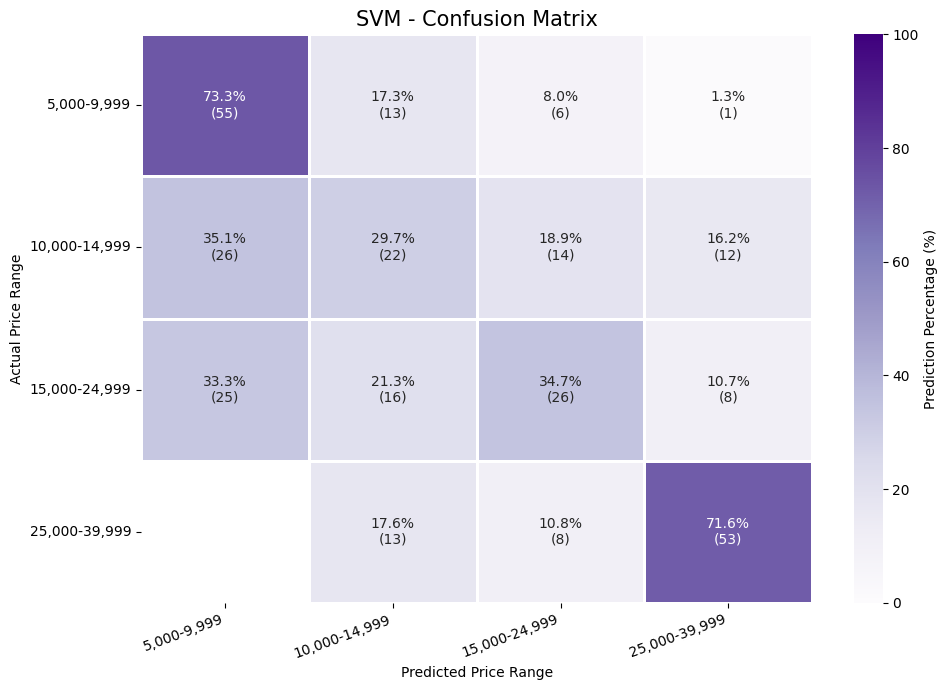

SVM Confusion Matrix:
[[55 13  6  1]
 [26 22 14 12]
 [25 16 26  8]
 [ 0 13  8 53]]


In [47]:
labels = sorted(
    y.unique(),
    key=lambda x: int(x.split("-")[0].replace(",", "").strip())
)

cm = confusion_matrix(
    y,
    y_pred,
    labels=labels
)

row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
) * 100

annotations = np.empty(cm.shape, dtype=object)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        if cm[i, j] == 0:
            annotations[i, j] = ""
        else:
            annotations[i, j] = (
                f"{cm_percent[i, j]:.1f}%\n({cm[i, j]})"
            )

mask = (cm == 0)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm_percent,
    annot=annotations,
    fmt="",
    cmap="Purples",
    mask=mask,
    xticklabels=labels,
    yticklabels=labels,
    linewidths=1,
    linecolor="white",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Prediction Percentage (%)"}
)

plt.title("SVM - Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")

plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("SVM Confusion Matrix:")
print(cm)

**Classification report**

In [48]:
print("SVM CLASSIFICATION REPORT")
print("--------------------------------")

print(
    classification_report(
        y,
        y_pred,
        labels=labels,
        zero_division=0
    )
)

SVM CLASSIFICATION REPORT
--------------------------------
               precision    recall  f1-score   support

  5,000-9,999       0.52      0.73      0.61        75
10,000-14,999       0.34      0.30      0.32        74
15,000-24,999       0.48      0.35      0.40        75
25,000-39,999       0.72      0.72      0.72        74

     accuracy                           0.52       298
    macro avg       0.52      0.52      0.51       298
 weighted avg       0.51      0.52      0.51       298



**Feature importance**

,Feature,Importance
3,RAM_GB,0.250000
4,Storage_GB,0.079530
2,Front_Camera_MP,0.060403
1,Rear_Camera_Count,0.055705
6,Display_Size_inches,0.053020
0,Rear_Main_Camera_MP,0.046980
5,Battery_mAh,0.040604


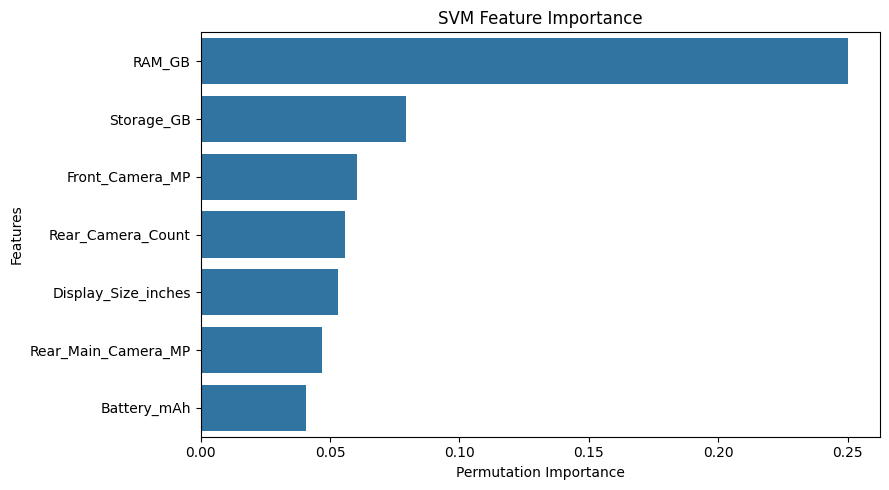

In [49]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    svm_model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("SVM Feature Importance")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

**Predict price range of a new mobile**

In [50]:
new_mobile = pd.DataFrame([{
    "Rear_Main_Camera_MP": 50,
    "Rear_Camera_Count": 3,
    "Front_Camera_MP": 16,
    "RAM_GB": 8,
    "Storage_GB": 128,
    "Battery_mAh": 5000,
    "Display_Size_inches": 6.5
}])

prediction = svm_model.predict(new_mobile)

print("NEW MOBILE PREDICTION")
print("-------------------------")

print("Predicted Price Range:", prediction[0])

NEW MOBILE PREDICTION
-------------------------
Predicted Price Range: 5,000-9,999


**Save and download trained model**

In [51]:
joblib.dump(
    svm_model,
    "mobile_price_prediction_SVM_model.pkl"
)

files.download(
    "mobile_price_prediction_SVM_model.pkl"
)

print("SVM Model Saved Successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

SVM Model Saved Successfully!
